# Leukemia (ALL) Classification - 4 Architectures

**Pipeline:** Import Libraries -> Load Dataset -> EDA -> Visualization -> Data Cleaning ->
Train-Test Split -> Train/Evaluate Model 1..4 -> Model Comparison -> Final Evaluation ->
Explainability (Grad-CAM) -> Save Model

| # | Architecture | Optimizer | Epochs | Backbone |
|---|---|---|---|---|
| 1 | CNN | SGD (lr=0.001) | 5 | from scratch |
| 2 | MobileNet | SGD (lr=0.001) | 5 | frozen |
| 3 | VGG19 | SGD (lr=0.001) | 5 | trainable |
| 4 | ResNet50 | SGD (lr=0.001) | 5 | trainable |

All metrics (accuracy, precision, recall, F1, AUC, training time) are written automatically to
`Results/leukemia/` on Google Drive: `comparison.csv`, `all_results.json`, `summary.xlsx`,
plus training curves and confusion matrices as images.


## Dataset

Source: `mehradaria/leukemia`. The four class folders (Benign, Early, Pre, Pro) must sit inside `Leukemia Dataset/Original`.

**Expected Drive layout:**
```
MyDrive/
└── Colab Notebooks/
    └── My Projects/
        └── Cancer Detection/
            ├── Leukemia Dataset/Original/
            │   ├── Benign/
            │   ├── Pre/
            │   ├── Pro/
            │   ├── Early/
            ├── Results/     (created automatically)
            └── Deploy/      (created automatically)
```

If your project folder has a different name, change `PROJECT_DIR` in the next cell.

In [ ]:
# ============================================================
#  0) Mount Google Drive and configure the project
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os

# ---------- Edit these two lines only ----------
PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks/My Projects'
DATA_PATH   = f'{PROJECT_DIR}/Leukemia Dataset'
# -----------------------------------------------

CANCER_TYPE = 'leukemia'
IMG_SIZE    = 256          # same value across all four notebooks
BATCH_SIZE  = 8
SPLIT       = 0.2
SEED        = 42

# Number of epochs per model (identical to the original scripts)
EPOCHS = {
    "CNN": 5,
    "MobileNet": 5,
    "VGG19": 5,
    "ResNet50": 5
}

RESULTS_DIR = f'{PROJECT_DIR}/Results/{CANCER_TYPE}'
for sub in ['', '/models', '/figures', '/histories', '/reports', '/predictions']:
    os.makedirs(RESULTS_DIR + sub, exist_ok=True)

assert os.path.isdir(DATA_PATH), f'Path not found: {DATA_PATH}'
print('DATA_PATH   :', DATA_PATH)
print('RESULTS_DIR :', RESULTS_DIR)
print('Dataset folders:', sorted(os.listdir(DATA_PATH))[:10])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_PATH   : /content/drive/MyDrive/Colab Notebooks/My Projects/Leukemia Dataset
RESULTS_DIR : /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia
Dataset folders: ['Benign', 'Early', 'Pre', 'Pro']


## 1) Import Libraries

In [ ]:
# ============================================================
#  1) Import Libraries
# ============================================================
import os, gc, json, time, hashlib, warnings
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

from sklearn.model_selection import train_test_split
from sklearn import metrics

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.applications import MobileNet, ResNet50
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

warnings.filterwarnings('ignore')
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow :', tf.__version__)
print('Keras      :', tf.keras.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))


TensorFlow : 2.20.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2) Load Dataset

In [ ]:
# ============================================================
#  2) Load Dataset - build a filepath/label table
# ============================================================
CLASS_DIRS = {
    "Benign": "Benign",
    "Pre": "Malignant_Pre-B",
    "Pro": "Malignant_Pro-B",
    "Early": "Malignant_early Pre-B"
}          # folder name -> final class label
CLASS_NAMES = list(CLASS_DIRS.values())
NUM_CLASSES = len(CLASS_NAMES)

rows = []
for folder, label in CLASS_DIRS.items():
    files = []
    for ext in ('*.jpeg', '*.jpg', '*.png', '*.JPG', '*.JPEG', '*.PNG', '*.tif', '*.bmp'):
        files += glob(os.path.join(DATA_PATH, folder, ext))
    if len(files) == 0:
        raise FileNotFoundError(f'No images found in: {os.path.join(DATA_PATH, folder)}')
    for f in files:
        rows.append({'filepath': f, 'label': label})

df = pd.DataFrame(rows).reset_index(drop=True)

# Fixed class ordering, so the label mapping never flips between sessions
LABEL2IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}
df['label_idx'] = df['label'].map(LABEL2IDX)

with open(f'{RESULTS_DIR}/class_names.json', 'w') as fh:
    json.dump({'cancer_type': CANCER_TYPE, 'class_names': CLASS_NAMES,
               'label2idx': LABEL2IDX, 'img_size': IMG_SIZE}, fh, indent=2)

print(f'Total images: {len(df)} | Classes: {NUM_CLASSES}')
df.head()


Total images: 3256 | Classes: 4


,filepath,label,label_idx
0,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
1,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
2,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
3,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
4,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0


## 3) EDA

In [ ]:
# ============================================================
#  3) EDA - Exploratory Data Analysis
# ============================================================
print('Class distribution:')
print(df['label'].value_counts(), '\n')

counts = df['label'].value_counts()
imbalance = counts.max() / counts.min()
print(f'Imbalance ratio (max/min): {imbalance:.2f}')

# Inspect image dimensions and color modes on a sample
sample = df.sample(min(120, len(df)), random_state=SEED)
info = []
for p in sample['filepath']:
    try:
        with Image.open(p) as im:
            info.append({'width': im.size[0], 'height': im.size[1], 'mode': im.mode,
                         'kb': os.path.getsize(p) / 1024})
    except Exception:
        pass
info = pd.DataFrame(info)
print('\nImage dimensions (sample):')
print(info[['width', 'height', 'kb']].describe().T[['mean', 'min', 'max']])
print('\nColor modes:', info['mode'].value_counts().to_dict())

eda_summary = {
    'n_images': int(len(df)),
    'n_classes': int(NUM_CLASSES),
    'class_counts': counts.to_dict(),
    'imbalance_ratio': float(imbalance),
    'width_mean': float(info['width'].mean()), 'height_mean': float(info['height'].mean()),
    'color_modes': {k: int(v) for k, v in info['mode'].value_counts().to_dict().items()},
}
with open(f'{RESULTS_DIR}/reports/eda_summary.json', 'w') as fh:
    json.dump(eda_summary, fh, indent=2)
eda_summary


Class distribution:
label
Malignant_early Pre-B    985
Malignant_Pre-B          963
Malignant_Pro-B          804
Benign                   504
Name: count, dtype: int64 

Imbalance ratio (max/min): 1.95

Image dimensions (sample):
            mean         min         max
width   224.0000  224.000000  224.000000
height  224.0000  224.000000  224.000000
kb       21.8462   13.959961   27.688477

Color modes: {'RGB': 120}


{'n_images': 3256,
 'n_classes': 4,
 'class_counts': {'Malignant_early Pre-B': 985,
  'Malignant_Pre-B': 963,
  'Malignant_Pro-B': 804,
  'Benign': 504},
 'imbalance_ratio': 1.9543650793650793,
 'width_mean': 224.0,
 'height_mean': 224.0,
 'color_modes': {'RGB': 120}}

## 4) Visualization

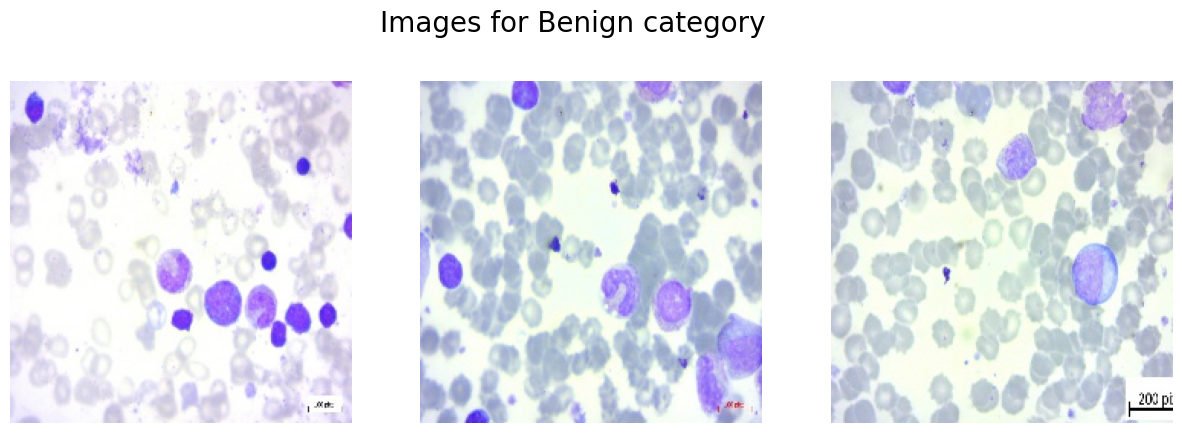

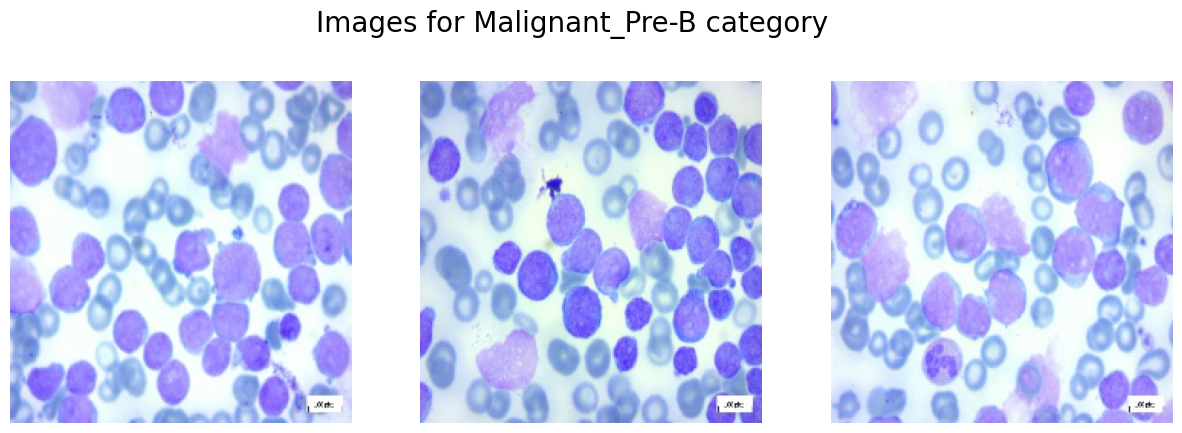

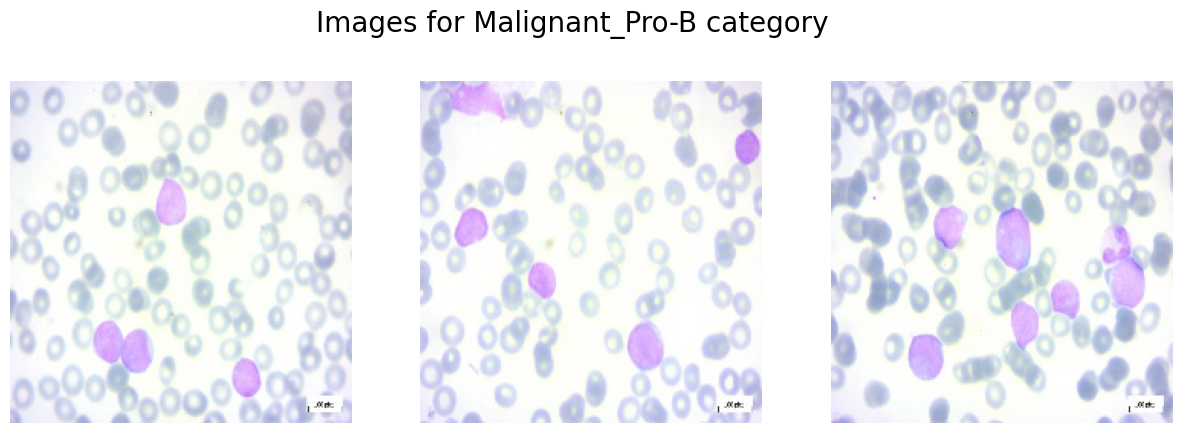

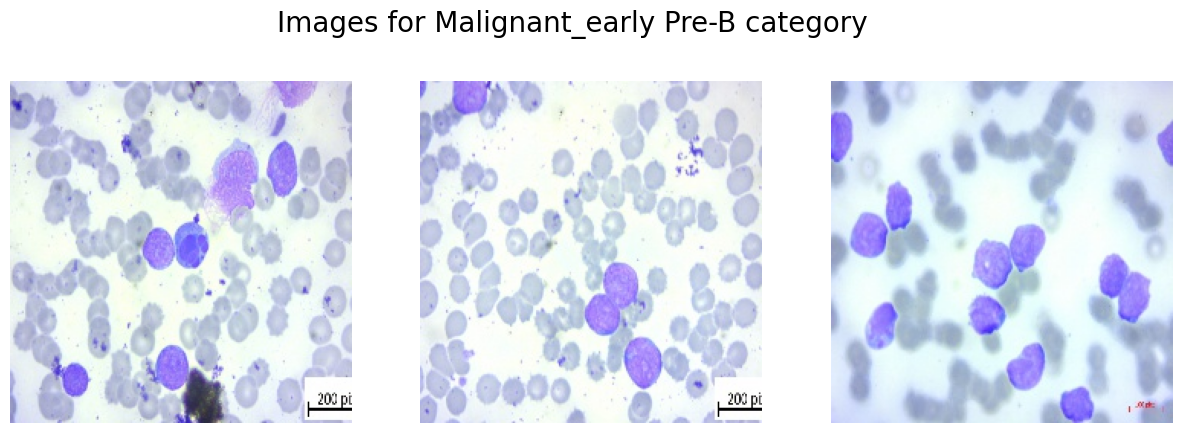

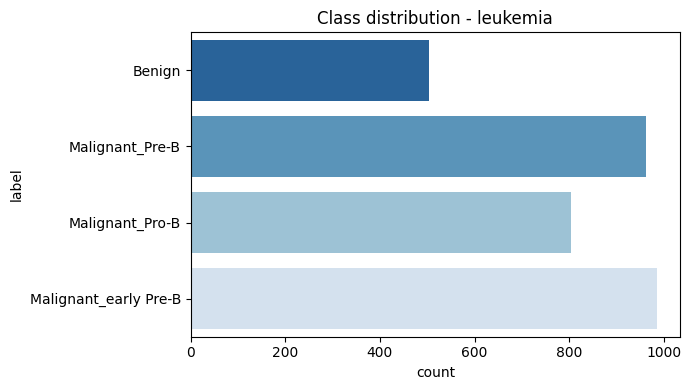

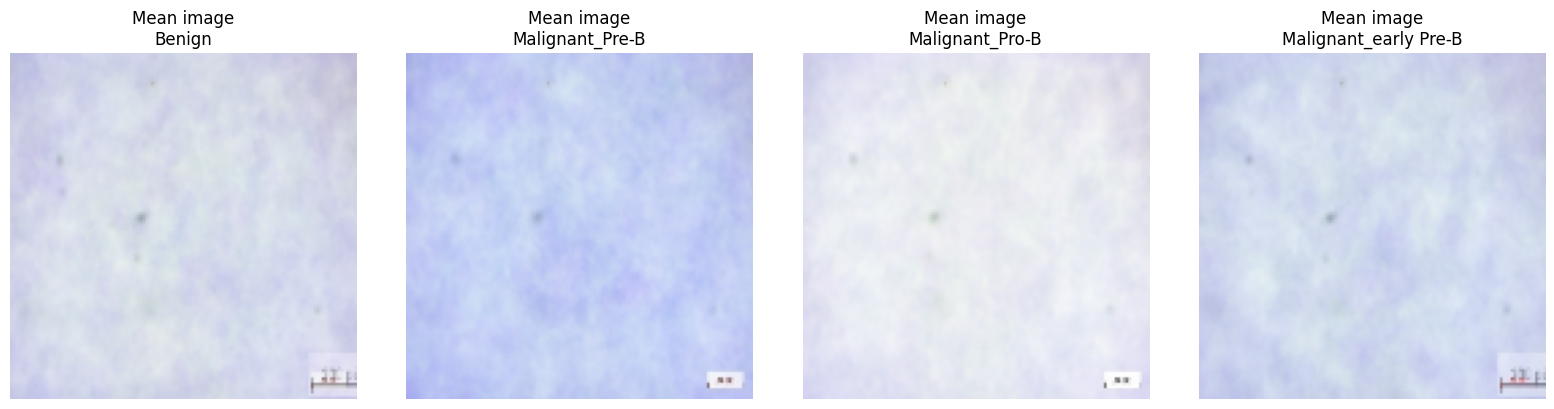

In [ ]:
# ============================================================
#  4) Visualization
# ============================================================
# 4.1 Random samples per class
for cls in CLASS_NAMES:
    paths = df[df.label == cls]['filepath'].sample(3, random_state=SEED).tolist()
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Images for {cls} category', fontsize=20)
    for i, p in enumerate(paths):
        ax[i].imshow(np.array(Image.open(p)))
        ax[i].axis('off')
    plt.show()

# 4.2 Class distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, y='label', order=CLASS_NAMES, palette='Blues_r')
plt.title(f'Class distribution - {CANCER_TYPE}')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/class_distribution.png', dpi=120)
plt.show()

# 4.3 Mean image per class - shows color/texture differences between classes
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 4))
axes = np.atleast_1d(axes)
for ax, cls in zip(axes, CLASS_NAMES):
    ps = df[df.label == cls]['filepath'].sample(min(60, (df.label == cls).sum()),
                                                random_state=SEED)
    acc = np.zeros((128, 128, 3), dtype=np.float64)
    for p in ps:
        acc += cv2.cvtColor(cv2.resize(cv2.imread(p), (128, 128)), cv2.COLOR_BGR2RGB)
    ax.imshow((acc / len(ps)).astype('uint8'))
    ax.set_title(f'Mean image\n{cls}')
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/mean_image_per_class.png', dpi=120)
plt.show()


## 5) Data Cleaning

In [ ]:
# # ============================================================
# #  5) Data Cleaning
# # ============================================================
# # (a) Detect corrupted or unreadable images
# bad = []
# for p in df['filepath']:
#     try:
#         with Image.open(p) as im:
#             im.verify()
#     except Exception:
#         bad.append(p)
# print(f'Corrupted images: {len(bad)}')

# # (b) Detect exact duplicates by file hash
# def file_hash(path, chunk=1 << 20):
#     h = hashlib.md5()
#     with open(path, 'rb') as fh:
#         while True:
#             b = fh.read(chunk)
#             if not b:
#                 break
#             h.update(b)
#     return h.hexdigest()

# df['hash'] = df['filepath'].apply(file_hash)
# dup_mask = df.duplicated('hash', keep='first')
# print(f'Duplicate images: {int(dup_mask.sum())}')

# # (c) Identical images assigned to different classes -> label conflict, always removed
# conflict = (df.groupby('hash')['label'].nunique() > 1)
# conflict_hashes = set(conflict[conflict].index)
# print(f'Label conflicts: {len(conflict_hashes)} hashes')

# DROP_DUPLICATES = True     # set to False to keep the dataset exactly as-is

# clean_log = {'corrupted': len(bad), 'duplicates': int(dup_mask.sum()),
#              'label_conflicts': len(conflict_hashes), 'drop_duplicates': DROP_DUPLICATES,
#              'n_before': int(len(df))}

# df = df[~df['filepath'].isin(bad)]
# df = df[~df['hash'].isin(conflict_hashes)]
# if DROP_DUPLICATES:
#     df = df[~df.duplicated('hash', keep='first')]
# df = df.drop(columns=['hash']).reset_index(drop=True)

# clean_log['n_after'] = int(len(df))
# with open(f'{RESULTS_DIR}/reports/cleaning_log.json', 'w') as fh:
#     json.dump(clean_log, fh, indent=2)

# print('\nAfter cleaning:', len(df), 'images')
# print(df['label'].value_counts())


## 6) Train-Test Split

train: (2604, 3) | val: (652, 3) | test: (977, 3)
Found 2604 validated image filenames belonging to 4 classes.
Found 652 validated image filenames belonging to 4 classes.
Found 977 validated image filenames belonging to 4 classes.
class_indices: {'Benign': 0, 'Malignant_Pre-B': 1, 'Malignant_Pro-B': 2, 'Malignant_early Pre-B': 3}


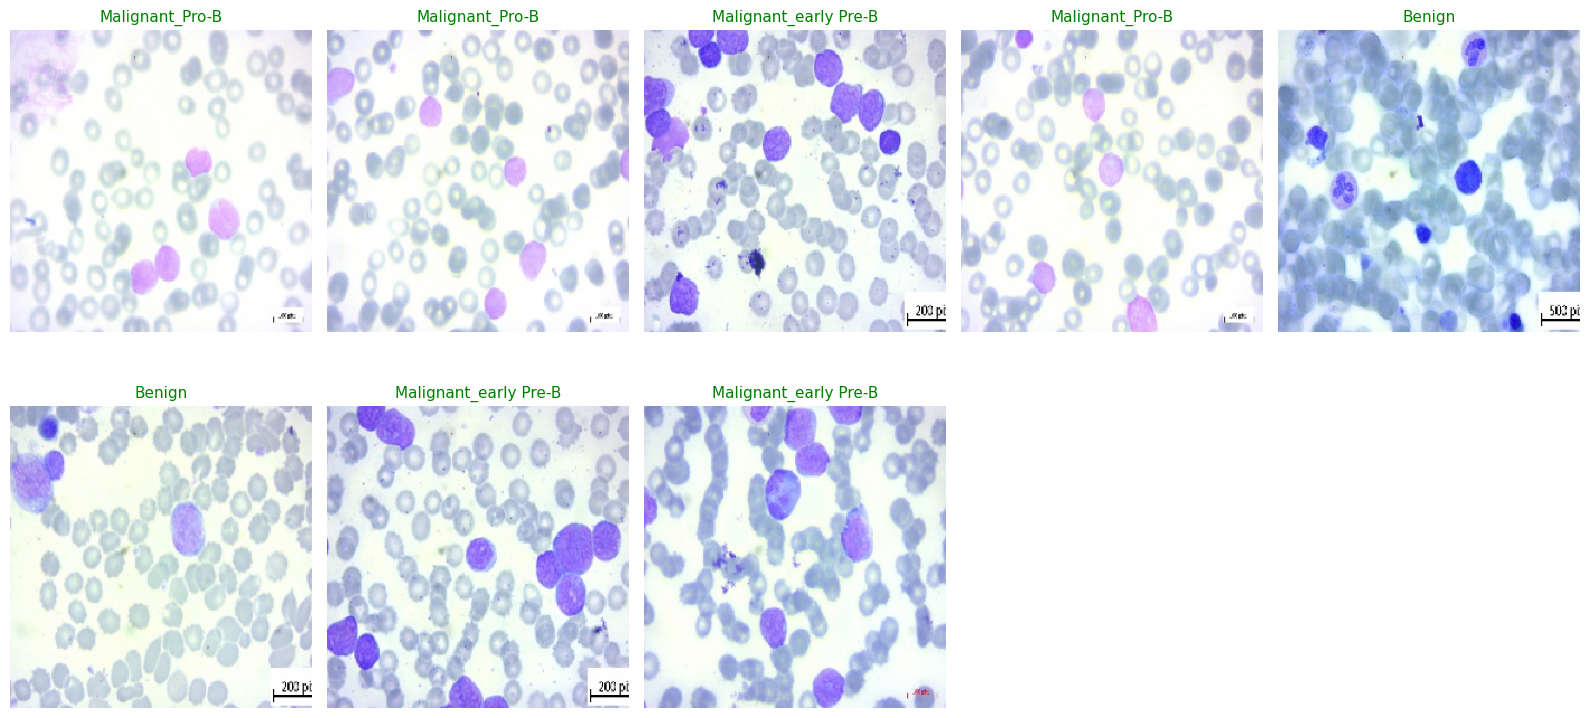

In [ ]:
# ============================================================
#  6) Train-Test Split and Data Generators
# ============================================================
# NOTE: the original script derived train_set/val_set from the FULL dataframe instead of
# from train_images, so test images leaked into training and inflated the reported scores.
# True  = reproduce the original behaviour exactly.
# False = correct sequential split with stratification.
REPRODUCE_ORIGINAL_SPLIT = True

if REPRODUCE_ORIGINAL_SPLIT:
    train_images, test_images = train_test_split(df, test_size=0.3, random_state=42)
    train_set,    val_set     = train_test_split(df, test_size=0.2, random_state=42)
else:
    train_val, test_images = train_test_split(
        df, test_size=0.3, random_state=42, stratify=df['label'])
    train_set, val_set = train_test_split(
        train_val, test_size=0.2, random_state=42, stratify=train_val['label'])

print('train:', train_set.shape, '| val:', val_set.shape, '| test:', test_images.shape)
if REPRODUCE_ORIGINAL_SPLIT:
    overlap = len(set(train_set['filepath']) & set(test_images['filepath']))
    print(f'WARNING: {overlap} images appear in both train and test')

image_gen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input)

common = dict(x_col='filepath', y_col='label', target_size=(IMG_SIZE, IMG_SIZE),
              color_mode='rgb', class_mode='categorical', classes=CLASS_NAMES,
              batch_size=BATCH_SIZE)

train = image_gen.flow_from_dataframe(dataframe=train_set,   shuffle=True,  seed=SEED, **common)
val   = image_gen.flow_from_dataframe(dataframe=val_set,     shuffle=False, **common)
test  = image_gen.flow_from_dataframe(dataframe=test_images, shuffle=False, **common)

assert list(train.class_indices.keys()) == CLASS_NAMES
y_true_test = test.classes
print('class_indices:', train.class_indices)

# Show one preprocessed batch
imgs, lbls = next(train)
plt.figure(figsize=(16, 8))
for i in range(min(10, len(lbls))):
    plt.subplot(2, 5, i + 1)
    plt.imshow((imgs[i] + 1) / 2)
    plt.title(CLASS_NAMES[int(np.argmax(lbls[i]))], color='green', fontsize=11)
    plt.axis('off')
plt.tight_layout(); plt.show()
train.reset()


## 7) Evaluation helpers and result logging

This cell defines `evaluate_and_log()`, called after every model. It writes:
- `comparison.csv` - one row per model with every metric
- `all_results.json` - full classification report and confusion matrix
- `summary.xlsx` - comparison sheet plus one sheet per model
- `figures/` - training curves and confusion matrices

In [ ]:
# ============================================================
#  7) Evaluation helpers and result logging
# ============================================================
COMPARISON_CSV = f'{RESULTS_DIR}/comparison.csv'
ALL_RESULTS_JSON = f'{RESULTS_DIR}/all_results.json'
SUMMARY_XLSX = f'{RESULTS_DIR}/summary.xlsx'

def _load_all_results():
    if os.path.exists(ALL_RESULTS_JSON):
        with open(ALL_RESULTS_JSON) as fh:
            return json.load(fh)
    return {}

def plot_history(model_name, history):
    """Plot and save loss/accuracy curves."""
    hdf = pd.DataFrame(history.history)
    hdf.index.name = 'epoch'
    hdf.to_csv(f'{RESULTS_DIR}/histories/{model_name}_history.csv')

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for k in ['loss', 'val_loss']:
        if k in hdf: ax[0].plot(hdf[k], label=k, marker='o')
    for k in ['accuracy', 'val_accuracy']:
        if k in hdf: ax[1].plot(hdf[k], label=k, marker='o')
    ax[0].set_title(f'{model_name} - Loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].set_title(f'{model_name} - Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/{model_name}_history.png', dpi=120)
    plt.show()
    return hdf

def plot_confusion(model_name, cm, normalize=False):
    data = cm.astype('float') / cm.sum(axis=1, keepdims=True) if normalize else cm
    plt.figure(figsize=(1.6 * NUM_CLASSES + 4, 1.4 * NUM_CLASSES + 3))
    sns.heatmap(data, annot=True, fmt='.2f' if normalize else 'd', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model_name}' + (' (normalized)' if normalize else ''))
    plt.tight_layout()
    suffix = '_cm_norm' if normalize else '_cm'
    plt.savefig(f'{RESULTS_DIR}/figures/{model_name}{suffix}.png', dpi=120)
    plt.show()

def evaluate_and_log(model_name, model, y_true, y_prob, history=None,
                     train_time=None, notes=''):
    """Compute every metric, plot it, and persist it to CSV/JSON/XLSX."""
    y_pred = np.argmax(y_prob, axis=1)

    acc = metrics.accuracy_score(y_true, y_pred)
    p_ma, r_ma, f_ma, _ = metrics.precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    p_w, r_w, f_w, _ = metrics.precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)
    try:
        auc = (metrics.roc_auc_score(y_true, y_prob[:, 1]) if NUM_CLASSES == 2
               else metrics.roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro'))
    except Exception:
        auc = float('nan')

    cm = metrics.confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    rep = metrics.classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_NAMES, output_dict=True,
                                        zero_division=0)

    print(metrics.classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_NAMES, zero_division=0))
    plot_confusion(model_name, cm)
    plot_confusion(model_name, cm, normalize=True)
    if history is not None:
        plot_history(model_name, history)

    # ---- persist ----
    pd.DataFrame(rep).T.to_csv(f'{RESULTS_DIR}/reports/{model_name}_classification_report.csv')
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        f'{RESULTS_DIR}/reports/{model_name}_confusion_matrix.csv')
    np.save(f'{RESULTS_DIR}/predictions/{model_name}_y_prob.npy', y_prob)
    np.save(f'{RESULTS_DIR}/predictions/{model_name}_y_true.npy', y_true)

    row = {
        'cancer_type': CANCER_TYPE, 'model': model_name,
        'accuracy': round(float(acc), 4),
        'precision_macro': round(float(p_ma), 4), 'recall_macro': round(float(r_ma), 4),
        'f1_macro': round(float(f_ma), 4),
        'precision_weighted': round(float(p_w), 4), 'recall_weighted': round(float(r_w), 4),
        'f1_weighted': round(float(f_w), 4),
        'auc': round(float(auc), 4) if auc == auc else None,
        'train_time_sec': round(float(train_time), 1) if train_time else None,
        'epochs': int(len(history.history['loss'])) if history is not None else None,
        'total_params': int(model.count_params()),
        'trainable_params': int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        'img_size': IMG_SIZE, 'batch_size': BATCH_SIZE, 'n_eval_samples': int(len(y_true)),
        'notes': notes,
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
    }
    for c in CLASS_NAMES:
        row[f'f1__{c}'] = round(float(rep[c]['f1-score']), 4)
        row[f'recall__{c}'] = round(float(rep[c]['recall']), 4)

    all_results = _load_all_results()
    all_results[model_name] = {'summary': row, 'classification_report': rep,
                               'confusion_matrix': cm.tolist()}
    with open(ALL_RESULTS_JSON, 'w') as fh:
        json.dump(all_results, fh, indent=2)

    comp = pd.DataFrame([v['summary'] for v in all_results.values()])
    comp = comp.sort_values('f1_macro', ascending=False).reset_index(drop=True)
    comp.to_csv(COMPARISON_CSV, index=False)
    try:
        with pd.ExcelWriter(SUMMARY_XLSX, engine='openpyxl') as xl:
            comp.to_excel(xl, sheet_name='comparison', index=False)
            for m, v in all_results.items():
                pd.DataFrame(v['classification_report']).T.to_excel(xl, sheet_name=m[:28])
    except Exception as e:
        print('XLSX export skipped:', e)

    print(f'\nSaved results for [{model_name}] to {RESULTS_DIR}')
    print(f'accuracy={acc:.4f}  f1_macro={f_ma:.4f}  auc={auc:.4f}')
    return row

def save_model_files(model_name, model):
    """Save the model in both formats."""
    p1 = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{model_name}.keras'
    p2 = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{model_name}.h5'
    model.save(p1); model.save(p2)
    print('Saved:', p1)
    return p1

def free_memory():
    """Release memory between models - important on Colab."""
    tf.keras.backend.clear_session()
    gc.collect()


In [ ]:
# ============================================================
#  Explainability helper: Grad-CAM
# ============================================================
CONV_TYPES = (layers.Conv2D, layers.DepthwiseConv2D, layers.SeparableConv2D)

def _last_conv_index(m):
    for i in range(len(m.layers) - 1, -1, -1):
        if isinstance(m.layers[i], CONV_TYPES):
            return i
    return None

def _gradcam_sequential(model, img, class_idx):
    """For the plain CNN: walk the layers one by one."""
    ci = _last_conv_index(model)
    with tf.GradientTape() as tape:
        x, conv_out = img, None
        for j, lyr in enumerate(model.layers):
            x = lyr(x, training=False)
            if j == ci:
                conv_out = x
                tape.watch(conv_out)
        preds = x
        idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
        loss = preds[:, idx]
    return tape.gradient(loss, conv_out), conv_out, preds, idx

def _gradcam_nested(model, img, class_idx):
    """For models wrapping a pretrained backbone (MobileNet / VGG19 / ResNet50)."""
    base = model.layers[0]
    ci = _last_conv_index(base)
    feat = tf.keras.Model(base.inputs, [base.layers[ci].output, base.output])
    with tf.GradientTape() as tape:
        conv_out, base_out = feat(img, training=False)
        tape.watch(conv_out)
        x = base_out
        for lyr in model.layers[1:]:
            x = lyr(x, training=False)
        preds = x
        idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
        loss = preds[:, idx]
    return tape.gradient(loss, conv_out), conv_out, preds, idx

def make_gradcam_heatmap(img_array, model, class_idx=None):
    img = tf.convert_to_tensor(np.asarray(img_array, dtype='float32'))
    fn = _gradcam_nested if isinstance(model.layers[0], tf.keras.Model) else _gradcam_sequential
    try:
        grads, conv_out, preds, idx = fn(model, img, class_idx)
        pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
        heat = tf.reduce_sum(conv_out[0] * pooled, axis=-1)
        heat = tf.maximum(heat, 0) / (tf.reduce_max(heat) + 1e-8)
        return heat.numpy(), preds.numpy()[0], int(idx)
    except Exception as e:
        # Fallback: saliency map (gradient of the output w.r.t. the input image)
        with tf.GradientTape() as tape:
            tape.watch(img)
            preds = model(img, training=False)
            idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
            loss = preds[:, idx]
        g = tape.gradient(loss, img)[0]
        heat = tf.reduce_max(tf.abs(g), axis=-1)
        heat = heat / (tf.reduce_max(heat) + 1e-8)
        print('Grad-CAM unavailable for this model, used saliency instead:', type(e).__name__)
        return heat.numpy(), preds.numpy()[0], int(idx)

def show_gradcam(model, img_disp, img_input, true_label=None, ax=None, alpha=0.4):
    heat, probs, idx = make_gradcam_heatmap(img_input, model)
    heat = cv2.resize(heat.astype('float32'), (img_disp.shape[1], img_disp.shape[0]))
    heat = cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(heat * alpha + img_disp * (1 - alpha))
    ax = ax or plt.gca()
    ax.imshow(overlay); ax.axis('off')
    t = f'pred: {CLASS_NAMES[idx]} ({probs[idx]:.2f})'
    if true_label is not None:
        t += f'\ntrue: {true_label}'
    ax.set_title(t, fontsize=10,
                 color=('green' if (true_label is None or true_label == CLASS_NAMES[idx]) else 'red'))


In [ ]:
PREPROCESS_NAME = 'mobilenet_v2'
print('Preprocessing used during training:', PREPROCESS_NAME)

Preprocessing used during training: mobilenet_v2


## Model 1: **CNN** - Train

In [ ]:
# ---- Train: CNN ----
MODEL_NAME = 'CNN'
free_memory()

model = keras.models.Sequential([
    layers.Conv2D(filters=32, kernel_size=(5, 5), activation='relu',
                  input_shape=(IMG_SIZE, IMG_SIZE, 3), padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    33,554,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,684,420 (128.50 MB)

 Trainable params: 33,683,652 (128.49 MB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 716s 2s/step - accuracy: 0.7174 - loss: 0.7607 - val_accuracy: 0.7147 - val_loss: 0.8211
Epoch 2/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8418 - loss: 0.4469 - val_accuracy: 0.5767 - val_loss: 1.4188
Epoch 3/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8786 - loss: 0.3538 - val_accuracy: 0.7684 - val_loss: 1.4549
Epoch 4/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9009 - loss: 0.2836 - val_accuracy: 0.4801 - val_loss: 1.5067
Epoch 5/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.9171 - loss: 0.2381 - val_accuracy: 0.6058 - val_loss: 1.6756
Training time: 12.7 minutes


### Model 1: **CNN** - Evaluation

Test set evaluation:
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.5988 - loss: 1.6684
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step
                       precision    recall  f1-score   support

               Benign       0.31      0.98      0.47       171
      Malignant_Pre-B       1.00      0.66      0.79       288
      Malignant_Pro-B       0.93      1.00      0.97       226
Malignant_early Pre-B       1.00      0.01      0.02       292

             accuracy                           0.60       977
            macro avg       0.81      0.66      0.56       977
         weighted avg       0.86      0.60      0.54       977



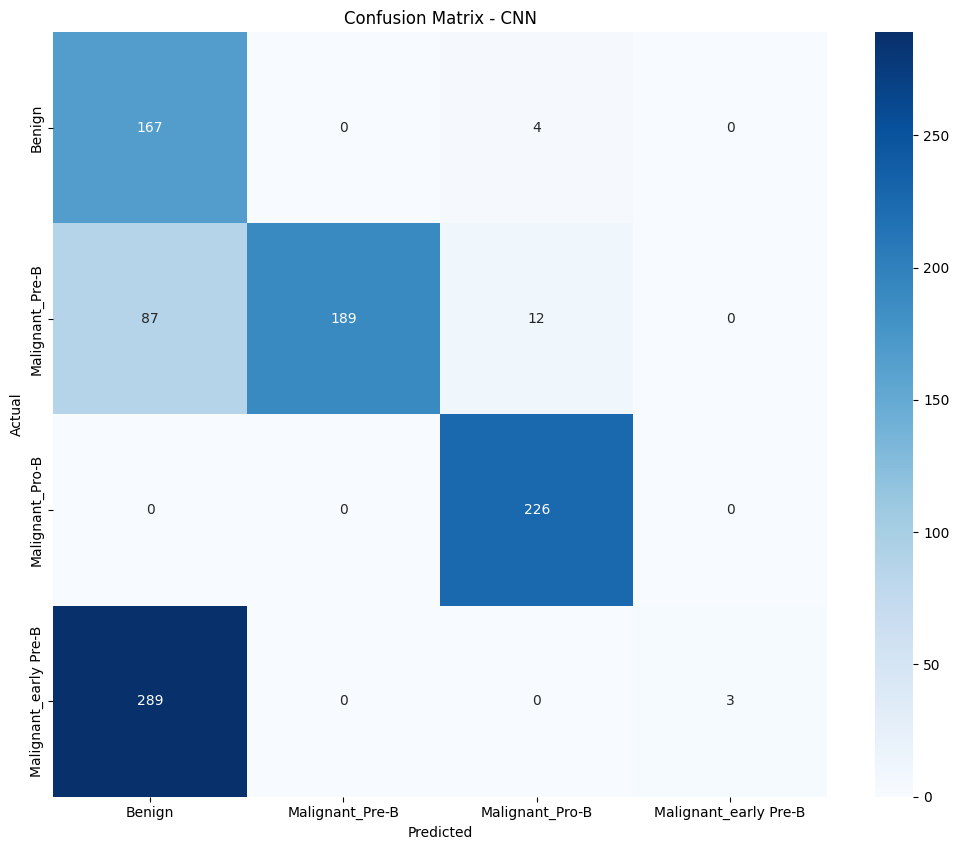

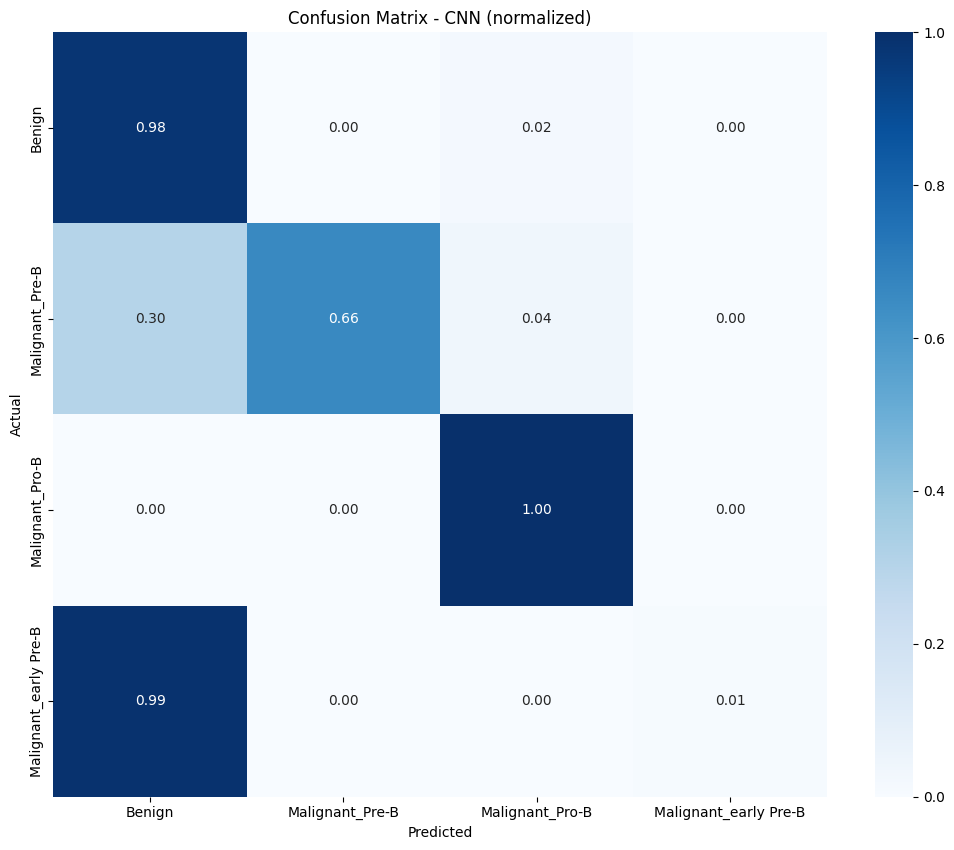

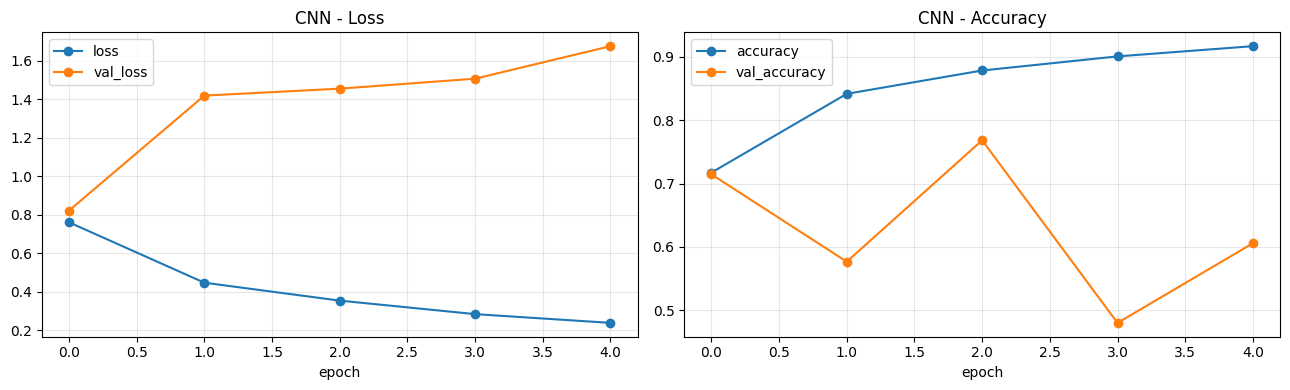


Saved results for [CNN] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia
accuracy=0.5988  f1_macro=0.5616  auc=0.9747


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia/models/leukemia_CNN.keras


In [ ]:
# ---- Evaluation: CNN ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='from scratch')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 2: **MobileNet** - Train

In [ ]:
# ---- Train: MobileNet ----
MODEL_NAME = 'MobileNet'
free_memory()

base = MobileNet(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False          # frozen backbone, same as the original script

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional) │ (None, 8, 8, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,526,212 (13.45 MB)

 Trainable params: 296,580 (1.13 MB)

 Non-trainable params: 3,229,632 (12.32 MB)

Epoch 1/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 48s 99ms/step - accuracy: 0.7016 - loss: 0.7612 - val_accuracy: 0.9156 - val_loss: 0.2849
Epoch 2/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8379 - loss: 0.4508 - val_accuracy: 0.9479 - val_loss: 0.1746
Epoch 3/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.8848 - loss: 0.3502 - val_accuracy: 0.9555 - val_loss: 0.1622
Epoch 4/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.9025 - loss: 0.2997 - val_accuracy: 0.9586 - val_loss: 0.1214
Epoch 5/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.9109 - loss: 0.2682 - val_accuracy: 0.9632 - val_loss: 0.1076
Training time: 1.7 minutes


### Model 2: **MobileNet** - Evaluation

Test set evaluation:
123/123 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - accuracy: 0.9693 - loss: 0.0948
123/123 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step
                       precision    recall  f1-score   support

               Benign       0.95      0.91      0.93       171
      Malignant_Pre-B       0.99      0.98      0.99       288
      Malignant_Pro-B       0.97      1.00      0.98       226
Malignant_early Pre-B       0.96      0.97      0.97       292

             accuracy                           0.97       977
            macro avg       0.97      0.96      0.97       977
         weighted avg       0.97      0.97      0.97       977



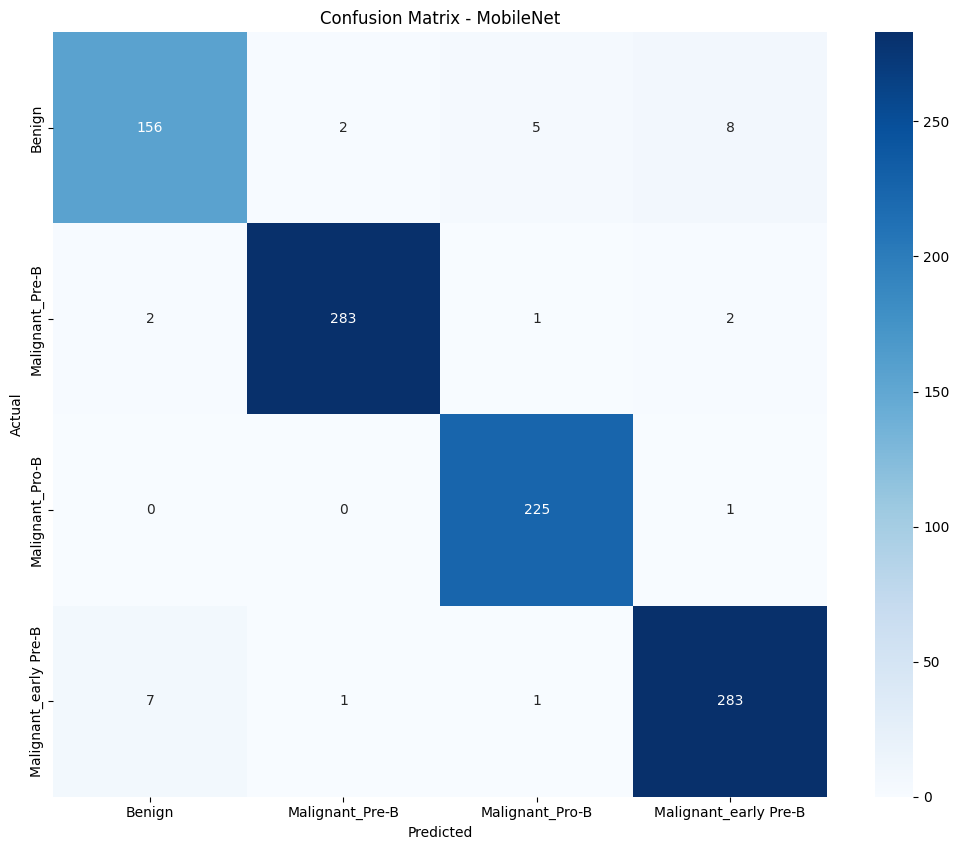

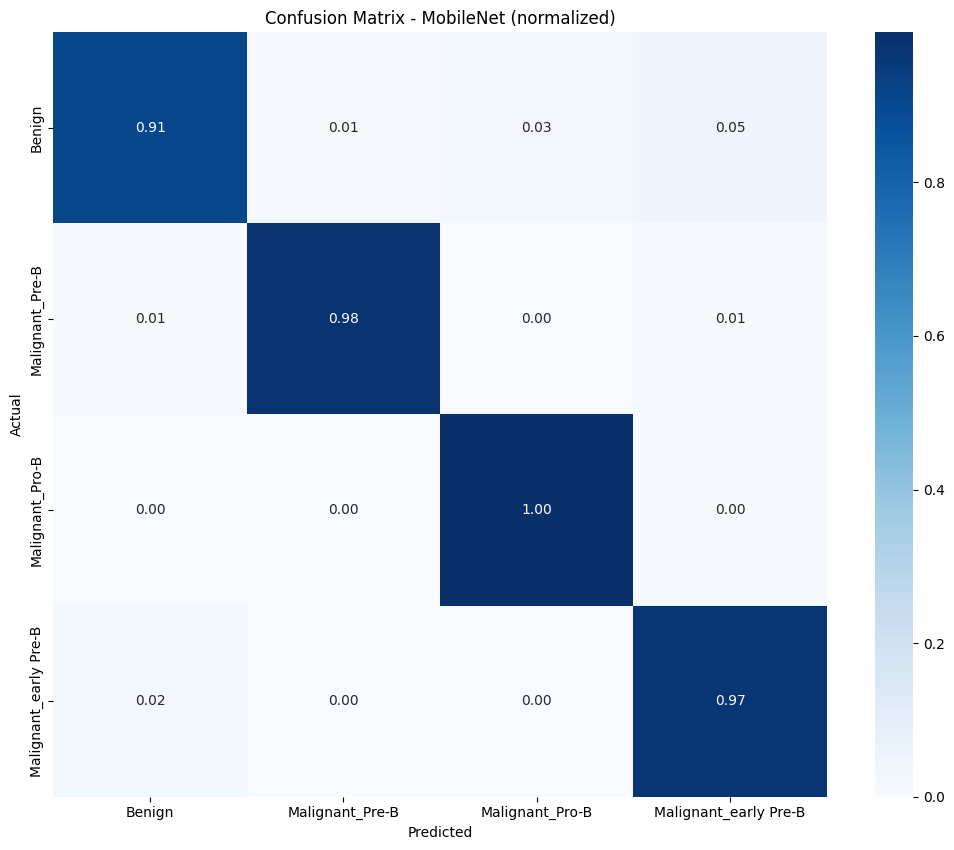

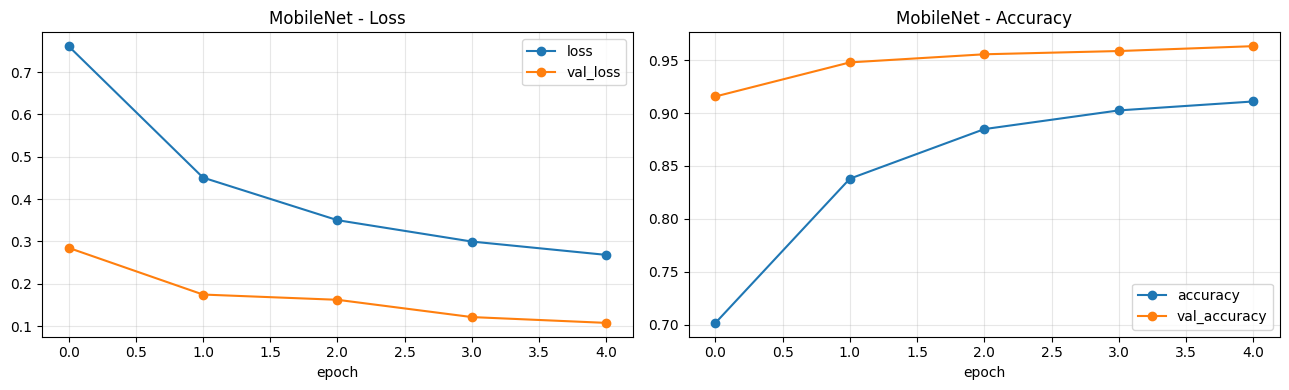


Saved results for [MobileNet] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia
accuracy=0.9693  f1_macro=0.9658  auc=0.9983


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia/models/leukemia_MobileNet.keras


In [ ]:
# ---- Evaluation: MobileNet ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='frozen backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 3: **VGG19** - Train

In [ ]:
# ---- Train: VGG19 ----
MODEL_NAME = 'VGG19'
free_memory()

base = VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
# Note: in the original script this backbone is NOT frozen, it is fully trainable

model = Sequential([
    base,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    16,777,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,966,852 (141.02 MB)

 Trainable params: 36,966,852 (141.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 146s 361ms/step - accuracy: 0.6686 - loss: 0.8272 - val_accuracy: 0.8681 - val_loss: 0.3693
Epoch 2/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 80s 244ms/step - accuracy: 0.8971 - loss: 0.3197 - val_accuracy: 0.9433 - val_loss: 0.1797
Epoch 3/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 80s 244ms/step - accuracy: 0.9528 - loss: 0.1609 - val_accuracy: 0.9877 - val_loss: 0.0358
Epoch 4/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 80s 245ms/step - accuracy: 0.9689 - loss: 0.1076 - val_accuracy: 0.9908 - val_loss: 0.0313
Epoch 5/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 80s 245ms/step - accuracy: 0.9773 - loss: 0.0801 - val_accuracy: 0.9877 - val_loss: 0.0267
Training time: 7.8 minutes


### Model 3: **VGG19** - Evaluation

Test set evaluation:
123/123 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - accuracy: 0.9877 - loss: 0.0271
123/123 ━━━━━━━━━━━━━━━━━━━━ 11s 87ms/step
                       precision    recall  f1-score   support

               Benign       0.97      0.97      0.97       171
      Malignant_Pre-B       0.99      1.00      0.99       288
      Malignant_Pro-B       0.99      1.00      1.00       226
Malignant_early Pre-B       1.00      0.98      0.99       292

             accuracy                           0.99       977
            macro avg       0.99      0.99      0.99       977
         weighted avg       0.99      0.99      0.99       977



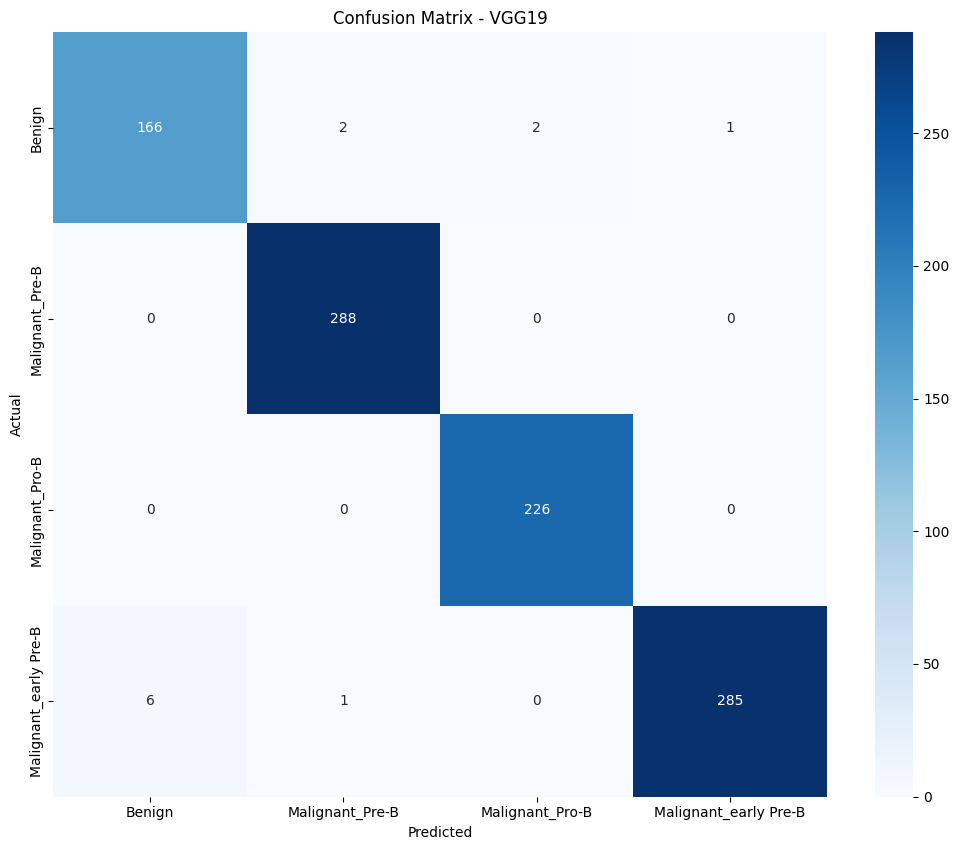

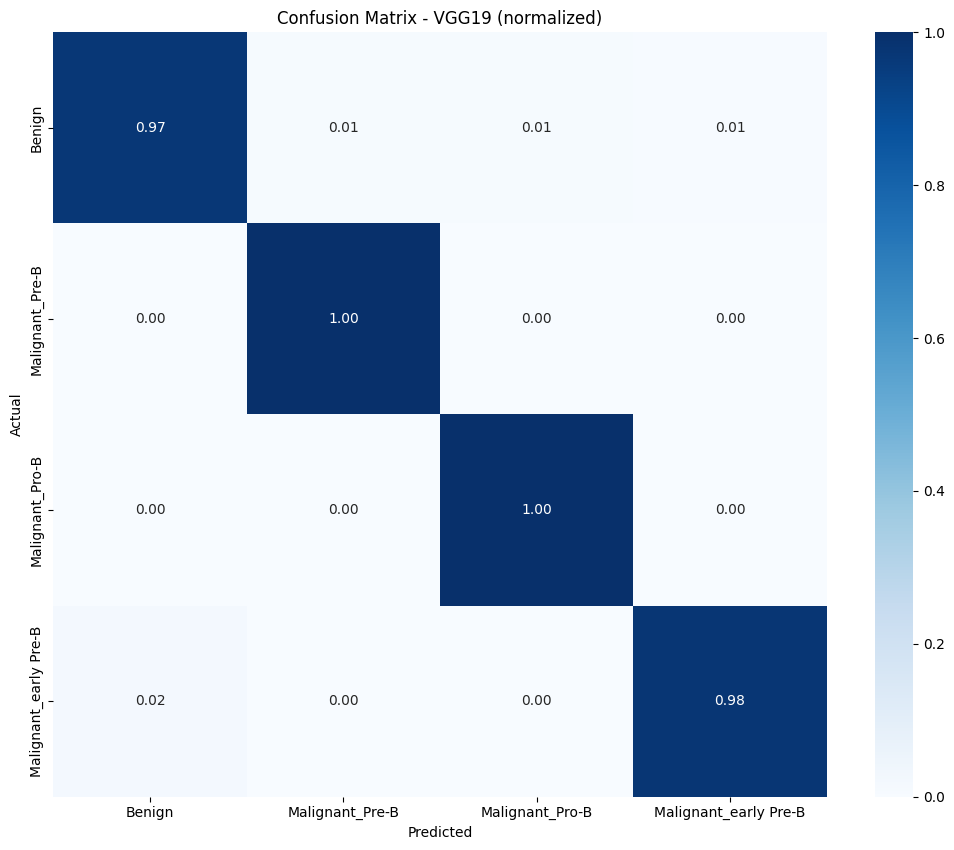

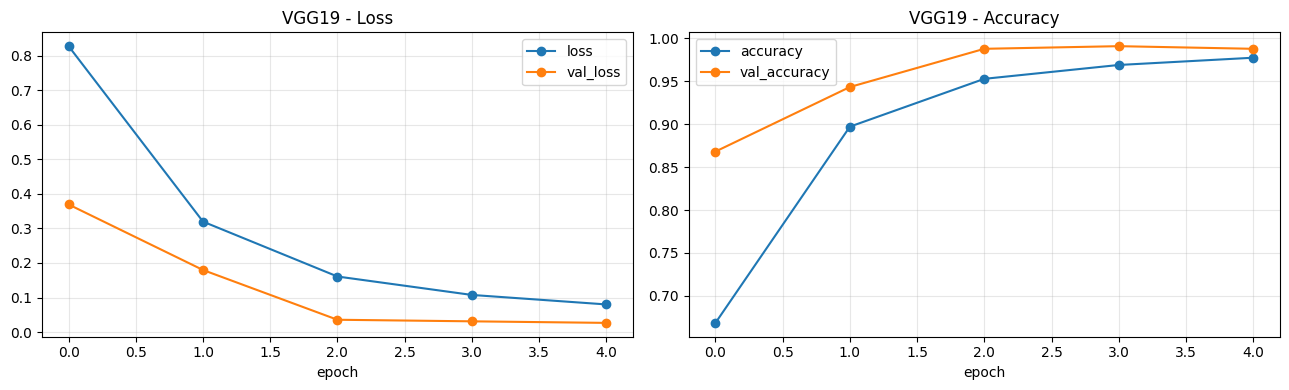


Saved results for [VGG19] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia
accuracy=0.9877  f1_macro=0.9861  auc=0.9999


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia/models/leukemia_VGG19.keras


In [ ]:
# ---- Evaluation: VGG19 ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='trainable backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 4: **ResNet50** - Train

In [ ]:
# ---- Train: ResNet50 ----
MODEL_NAME = 'ResNet50'
free_memory()

base = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
# Note: in the original script this backbone is NOT frozen, it is fully trainable

model = Sequential([
    base,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    67,109,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,861,828 (346.61 MB)

 Trainable params: 90,808,708 (346.41 MB)

 Non-trainable params: 53,120 (207.50 KB)

Epoch 1/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 97s 199ms/step - accuracy: 0.7922 - loss: 0.5832 - val_accuracy: 0.2929 - val_loss: 7.7207
Epoch 2/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 39s 119ms/step - accuracy: 0.9520 - loss: 0.1608 - val_accuracy: 0.2960 - val_loss: 2.6132
Epoch 3/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 41s 126ms/step - accuracy: 0.9651 - loss: 0.0950 - val_accuracy: 0.9340 - val_loss: 0.2168
Epoch 4/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - accuracy: 0.9835 - loss: 0.0465 - val_accuracy: 0.9923 - val_loss: 0.0457
Epoch 5/5
326/326 ━━━━━━━━━━━━━━━━━━━━ 39s 118ms/step - accuracy: 0.9858 - loss: 0.0369 - val_accuracy: 0.9969 - val_loss: 0.0116
Training time: 4.2 minutes


### Model 4: **ResNet50** - Evaluation

Test set evaluation:
123/123 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.9980 - loss: 0.0081
123/123 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step
                       precision    recall  f1-score   support

               Benign       1.00      0.99      1.00       171
      Malignant_Pre-B       1.00      1.00      1.00       288
      Malignant_Pro-B       1.00      1.00      1.00       226
Malignant_early Pre-B       1.00      1.00      1.00       292

             accuracy                           1.00       977
            macro avg       1.00      1.00      1.00       977
         weighted avg       1.00      1.00      1.00       977



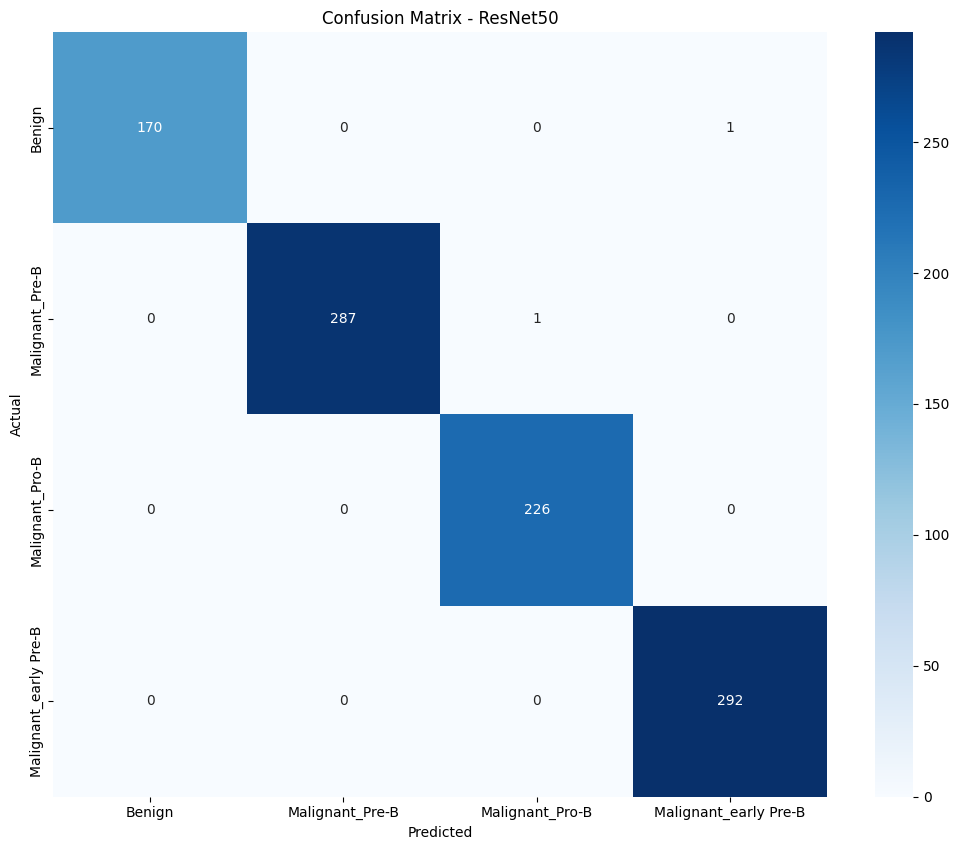

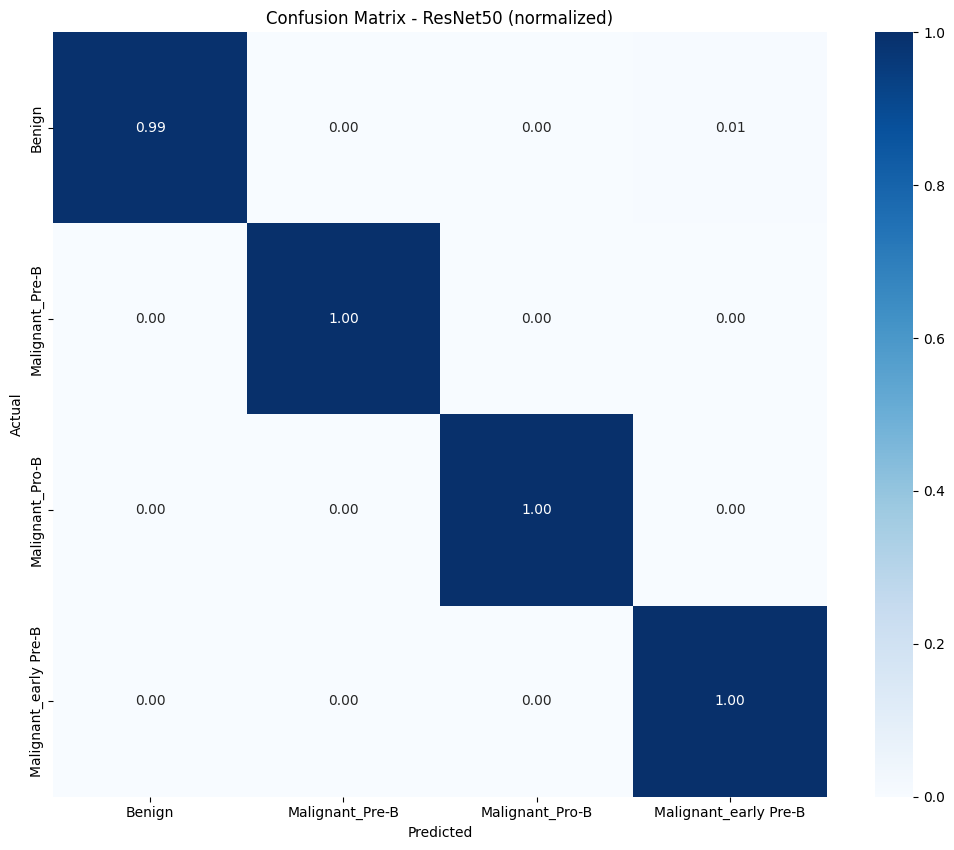

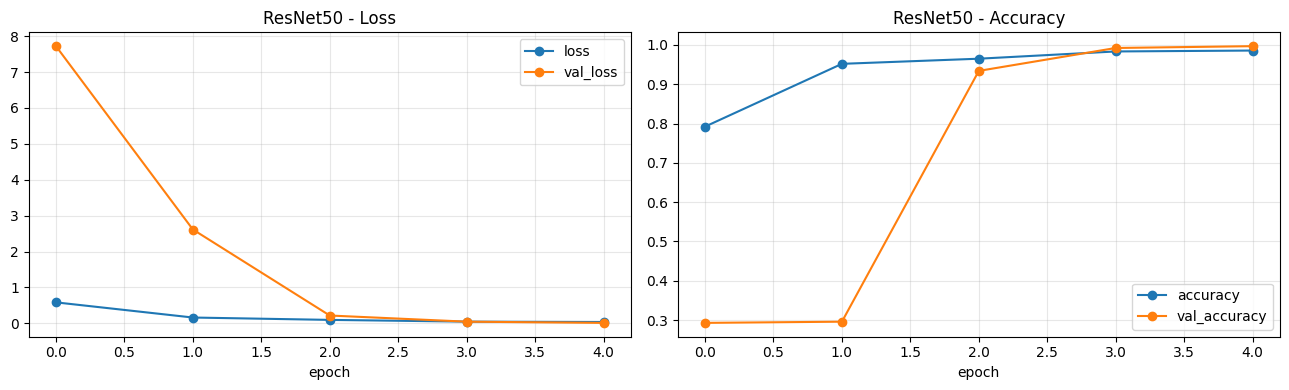


Saved results for [ResNet50] to /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia
accuracy=0.9980  f1_macro=0.9979  auc=1.0000


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia/models/leukemia_ResNet50.keras


In [ ]:
# ---- Evaluation: ResNet50 ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='trainable backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## 8) Model Comparison

,model,accuracy,precision_macro,recall_macro,f1_macro,auc,train_time_sec,total_params
0,ResNet50,0.9980,0.9980,0.9977,0.9979,1.0000,254.6,90861828
1,VGG19,0.9877,0.9856,0.9867,0.9861,0.9999,465.2,36966852
2,MobileNet,0.9693,0.9668,0.9649,0.9658,0.9983,103.5,3526212
3,CNN,0.5988,0.8104,0.6608,0.5616,0.9747,764.1,33684420


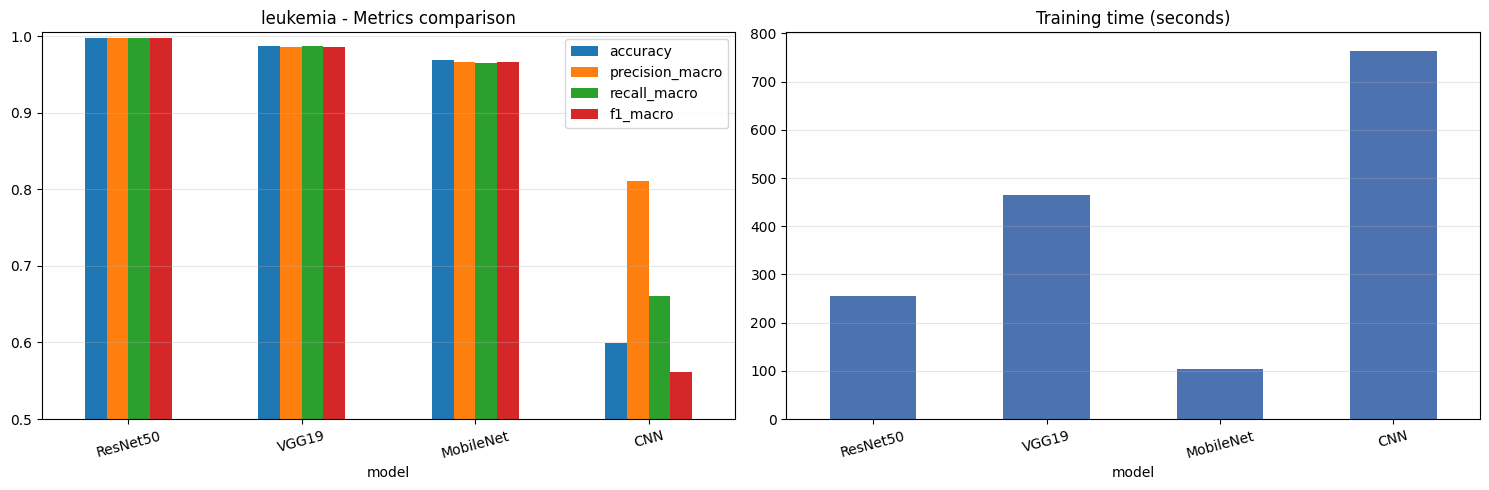

Best model by F1-macro: ResNet50 (accuracy=0.9980, f1=0.9979)


In [ ]:
# ============================================================
#  8) Model Comparison
# ============================================================
comp = pd.read_csv(COMPARISON_CSV)
display(comp[['model', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
              'auc', 'train_time_sec', 'total_params']])

m = comp.set_index('model')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
m[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']].plot.bar(ax=ax[0], rot=15)
ax[0].set_ylim(min(0.5, m['f1_macro'].min() - 0.05), 1.005)
ax[0].set_title(f'{CANCER_TYPE} - Metrics comparison'); ax[0].grid(axis='y', alpha=.3)
m[['train_time_sec']].plot.bar(ax=ax[1], rot=15, color='#4c72b0', legend=False)
ax[1].set_title('Training time (seconds)'); ax[1].grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/model_comparison.png', dpi=120)
plt.show()

BEST_MODEL = comp.iloc[0]['model']
print(f'Best model by F1-macro: {BEST_MODEL} '
      f'(accuracy={comp.iloc[0]["accuracy"]:.4f}, f1={comp.iloc[0]["f1_macro"]:.4f})')


## 9) Final Evaluation

=== Final report: ResNet50 ===
                       precision    recall  f1-score   support

               Benign       1.00      0.99      1.00       171
      Malignant_Pre-B       1.00      1.00      1.00       288
      Malignant_Pro-B       1.00      1.00      1.00       226
Malignant_early Pre-B       1.00      1.00      1.00       292

             accuracy                           1.00       977
            macro avg       1.00      1.00      1.00       977
         weighted avg       1.00      1.00      1.00       977



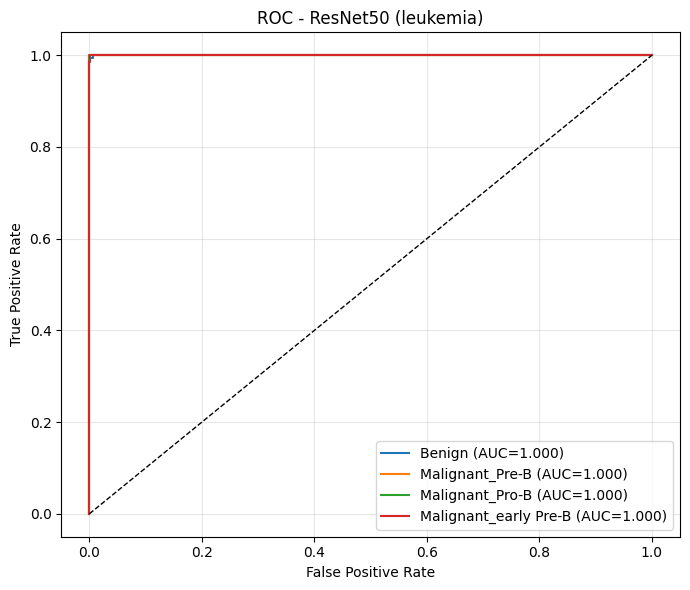

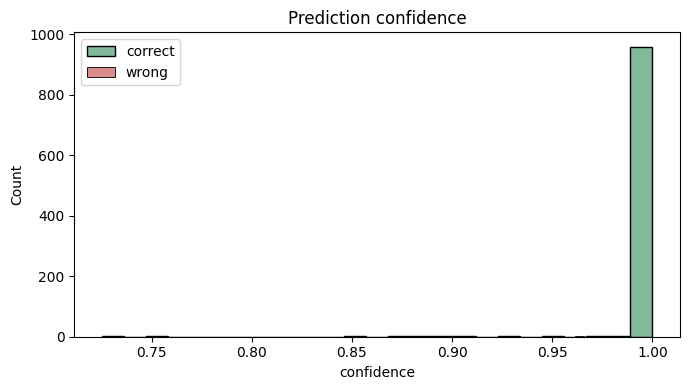

Errors: 2 out of 977
Mean confidence on wrong predictions: 0.907


In [ ]:
# ============================================================
#  9) Final Evaluation - detailed report for the best model
# ============================================================
best_path = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.keras'
best_model = tf.keras.models.load_model(best_path)

y_prob_best = np.load(f'{RESULTS_DIR}/predictions/{BEST_MODEL}_y_prob.npy')
y_true_best = np.load(f'{RESULTS_DIR}/predictions/{BEST_MODEL}_y_true.npy')
y_pred_best = y_prob_best.argmax(1)

print(f'=== Final report: {BEST_MODEL} ===')
print(metrics.classification_report(y_true_best, y_pred_best,
                                    labels=list(range(NUM_CLASSES)),
                                    target_names=CLASS_NAMES, zero_division=0))

# Per-class ROC curves
plt.figure(figsize=(7, 6))
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = metrics.roc_curve((y_true_best == i).astype(int), y_prob_best[:, i])
    plt.plot(fpr, tpr, label=f'{c} (AUC={metrics.auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title(f'ROC - {BEST_MODEL} ({CANCER_TYPE})'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/final_roc.png', dpi=120); plt.show()

# Confidence distribution: correct vs wrong predictions
conf = y_prob_best.max(1)
correct = y_pred_best == y_true_best
plt.figure(figsize=(7, 4))
sns.histplot(conf[correct], bins=25, label='correct', color='seagreen', alpha=.6)
sns.histplot(conf[~correct], bins=25, label='wrong', color='indianred', alpha=.7)
plt.xlabel('confidence'); plt.legend(); plt.title('Prediction confidence')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/final_confidence.png', dpi=120); plt.show()

print(f'Errors: {int((~correct).sum())} out of {len(correct)}')
if (~correct).any():
    print('Mean confidence on wrong predictions: %.3f' % conf[~correct].mean())


## 10) Explainability - Grad-CAM

Red regions are the areas the model relied on. If the model focuses on the background or the image borders instead of the tissue, the problem is in the data rather than in the architecture.

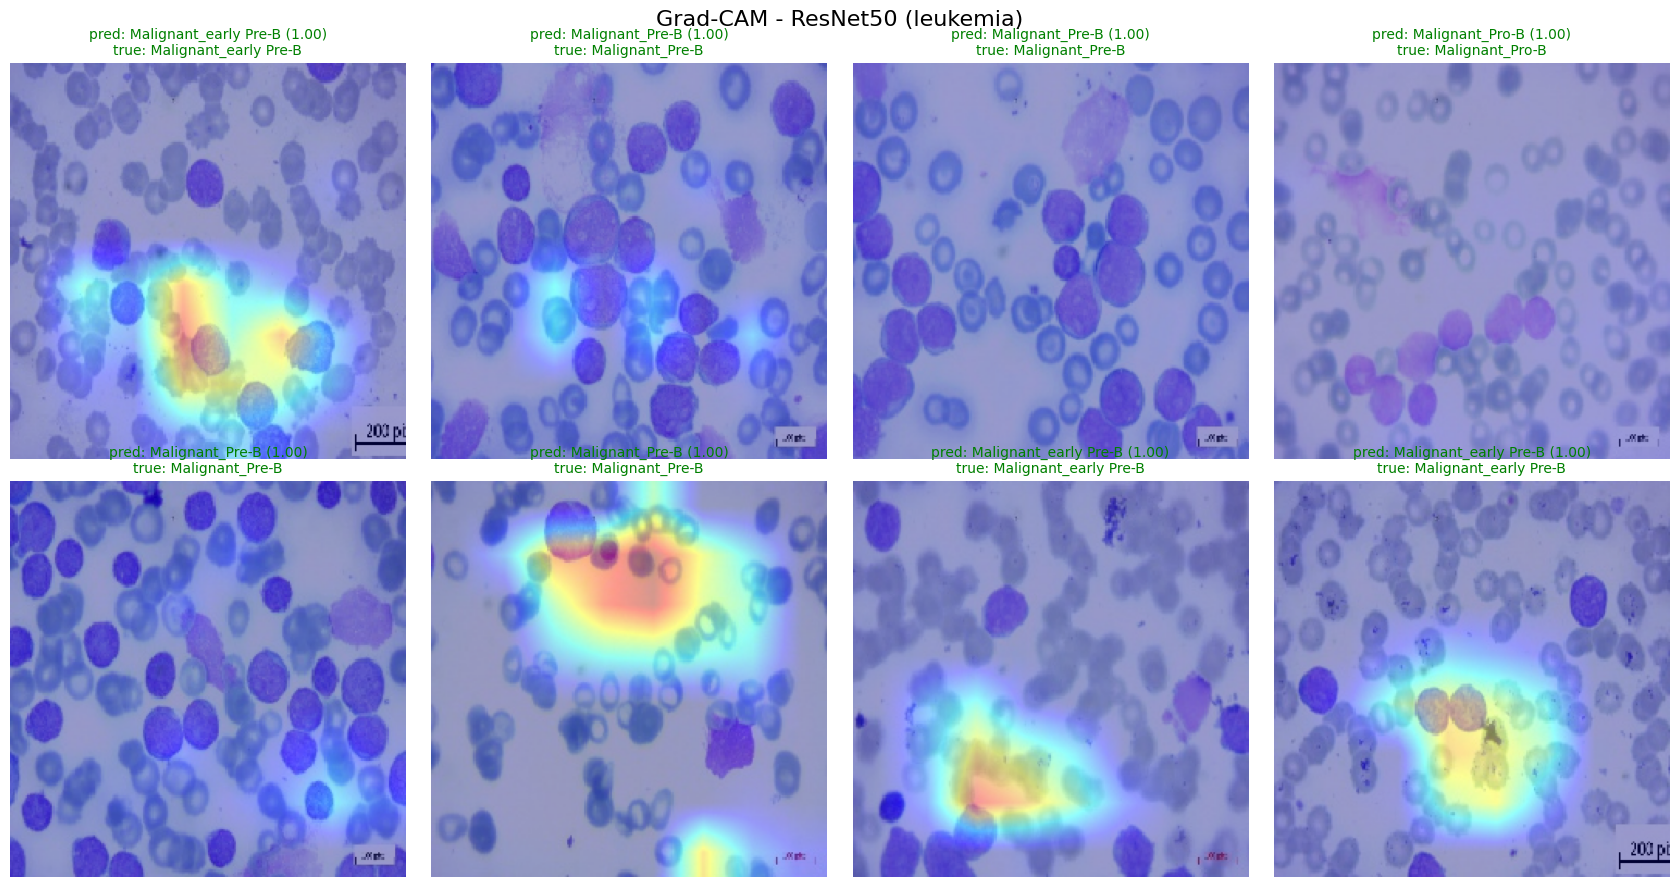

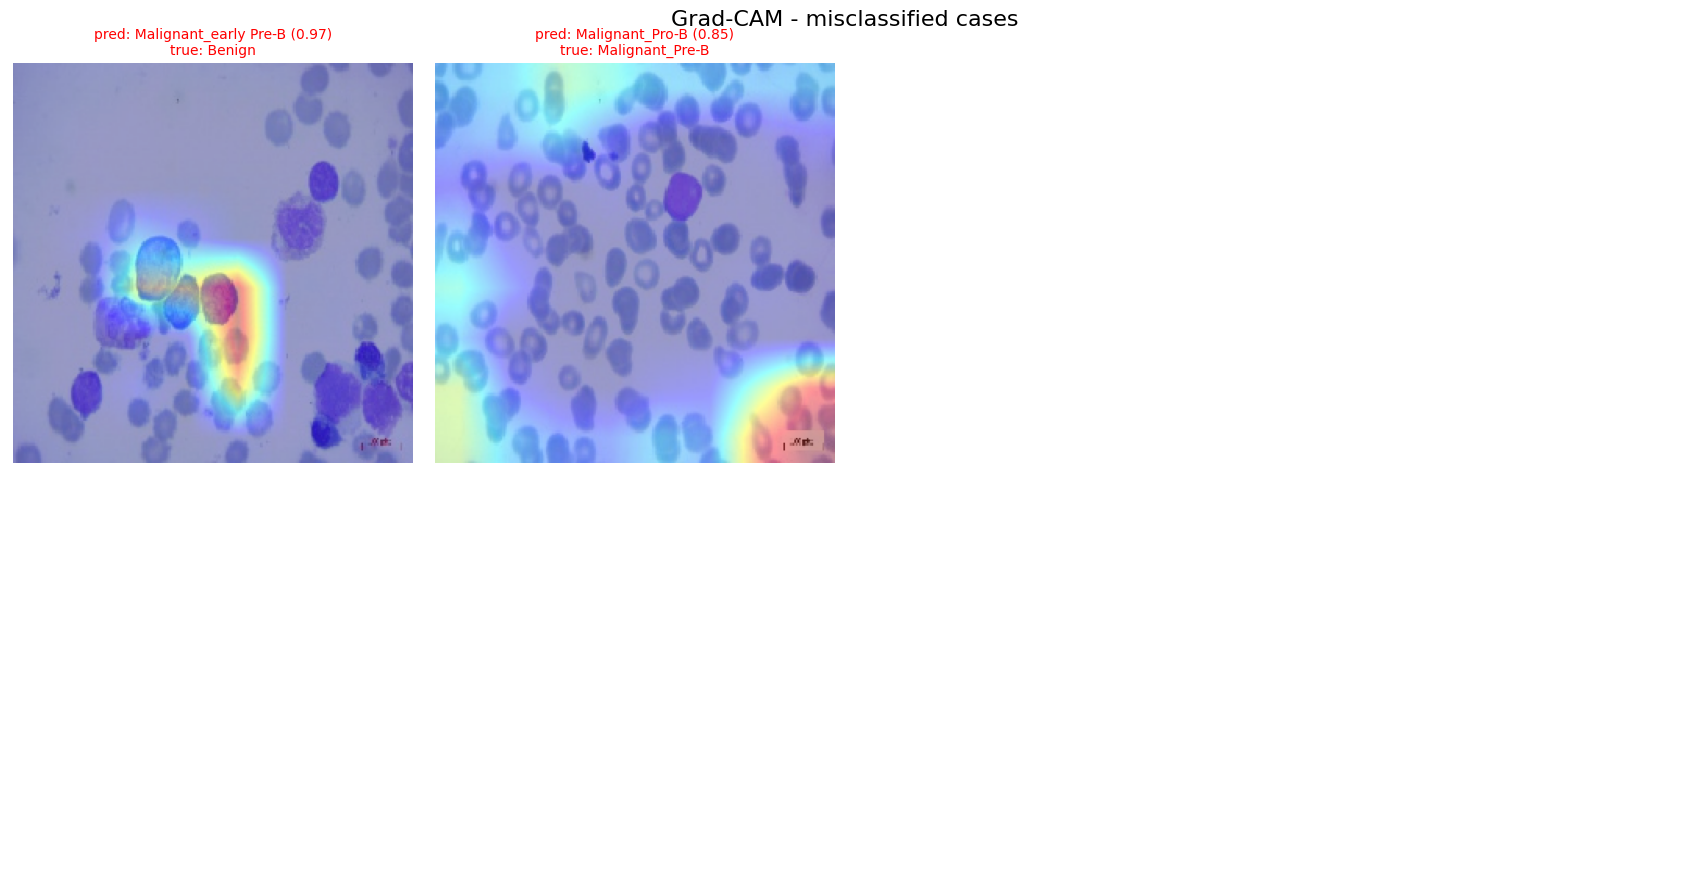

In [ ]:
# ============================================================
#  10) Explainability - Grad-CAM on the best model
# ============================================================
test_paths = np.array(test.filepaths)
rng = np.random.RandomState(SEED)
idxs = rng.choice(len(test_paths), 8, replace=False)

def _load_pair(path):
    img = load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
    disp = np.array(img)
    inp = np.expand_dims(
        tf.keras.applications.mobilenet_v2.preprocess_input(img_to_array(img)), 0)
    return disp, inp

fig, axes = plt.subplots(2, 4, figsize=(17, 9))
fig.suptitle(f'Grad-CAM - {BEST_MODEL} ({CANCER_TYPE})', fontsize=16)
for ax, i in zip(axes.ravel(), idxs):
    disp, inp = _load_pair(test_paths[i])
    show_gradcam(best_model, disp, inp, CLASS_NAMES[y_true_best[i]], ax=ax)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/gradcam_samples.png', dpi=120)
plt.show()

wrong = np.where(y_pred_best != y_true_best)[0]
if len(wrong):
    sel = wrong[:8]
    fig, axes = plt.subplots(2, 4, figsize=(17, 9))
    fig.suptitle('Grad-CAM - misclassified cases', fontsize=16)
    for ax, i in zip(axes.ravel(), sel):
        disp, inp = _load_pair(test_paths[i])
        show_gradcam(best_model, disp, inp, CLASS_NAMES[y_true_best[i]], ax=ax)
    for ax in axes.ravel()[len(sel):]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/gradcam_errors.png', dpi=120)
    plt.show()
else:
    print('No misclassified samples')

## 11) Save Model

In [ ]:
# ============================================================
#  11) Save Model and export a deployment bundle
# ============================================================
DEPLOY_DIR = f'{PROJECT_DIR}/Deploy/{CANCER_TYPE}'
os.makedirs(DEPLOY_DIR, exist_ok=True)

import shutil
shutil.copy(f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.keras',
            f'{DEPLOY_DIR}/{CANCER_TYPE}_best.keras')
shutil.copy(f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.h5',
            f'{DEPLOY_DIR}/{CANCER_TYPE}_best.h5')

meta = {
    'cancer_type': CANCER_TYPE,
    'architecture': BEST_MODEL,
    'class_names': CLASS_NAMES,          # exact order of the softmax outputs
    'img_size': IMG_SIZE,
    'preprocessing': PREPROCESS_NAME,    # must match the preprocessing used during training
    'metrics': comp.iloc[0].to_dict(),
    'saved_at': time.strftime('%Y-%m-%d %H:%M:%S'),
}
with open(f'{DEPLOY_DIR}/model_meta.json', 'w') as fh:
    json.dump(meta, fh, indent=2, default=str)

print('Deployment bundle saved to:', DEPLOY_DIR)
for f in sorted(os.listdir(DEPLOY_DIR)):
    print(' -', f)
print('\nAll results:', RESULTS_DIR)
print(' - comparison.csv / all_results.json / summary.xlsx')


Deployment bundle saved to: /content/drive/MyDrive/Colab Notebooks/My Projects/Deploy/leukemia
 - leukemia_best.h5
 - leukemia_best.keras
 - model_meta.json

All results: /content/drive/MyDrive/Colab Notebooks/My Projects/Results/leukemia
 - comparison.csv / all_results.json / summary.xlsx


In [ ]:
# ============================================================
#  Quick check: predict a single image using the training preprocessing.
#  This is the exact same logic used by the Flask API.
# ============================================================
def predict_image(image_path, model=None, meta_path=f'{DEPLOY_DIR}/model_meta.json'):
    with open(meta_path) as fh:
        meta = json.load(fh)
    model = model or tf.keras.models.load_model(
        f'{DEPLOY_DIR}/{meta["cancer_type"]}_best.keras')
    size = meta['img_size']

    if meta['preprocessing'] == 'bgr_raw':
        # Colon / Lung training: cv2.imread (BGR) + resize, no normalization
        arr = cv2.resize(cv2.imread(image_path), (size, size)).astype('float32')
    else:
        # Leukemia / Skin training: RGB + mobilenet_v2.preprocess_input
        img = load_img(image_path, target_size=(size, size))
        arr = tf.keras.applications.mobilenet_v2.preprocess_input(img_to_array(img))

    arr = np.expand_dims(arr, 0)
    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    return {'label': meta['class_names'][idx],
            'confidence': float(probs[idx]),
            'all_probs': dict(zip(meta['class_names'], probs.round(4).tolist()))}

sample_path = df['filepath'].iloc[0]
print('Image:', os.path.basename(sample_path), '| Ground truth:', df['label'].iloc[0])
predict_image(sample_path)


Image: WBC-Benign-117.jpg | Ground truth: Benign


{'label': 'Benign',
 'confidence': 0.9999055862426758,
 'all_probs': {'Benign': 0.9998999834060669,
  'Malignant_Pre-B': 0.0,
  'Malignant_Pro-B': 0.0,
  'Malignant_early Pre-B': 9.999999747378752e-05}}

---
### Done

Everything is stored under `Results/leukemia/` and `Deploy/leukemia/` on Google Drive.

These models are for research and academic use only, not a medical diagnostic tool.